# BÀI THỰC HÀNH 2: MẠNG NEURAL TÍCH CHẬP

<b>Hướng dẫn nộp bài:</b> Các bạn commit và push code lên github, sử dụng file txt đặt tên theo cú pháp <MSSV>.txt chứa đường link dẫn đến github của bài thực hành và nộp file txt này tên courses..

Bộ dữ liệu sử dụng: [VinaFood21 dataset](https://arxiv.org/abs/2108.02929).

Link download: https://drive.google.com/file/d/1UpZOf0XlwvB4rKpyZ35iwTA8oWHqDBbR/view?usp=share_link.

## Chuẩn bị chung




In [1]:
import json
import os
import random
import subprocess
import sys
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import torch
import torch.nn as nn
from IPython.display import display
from sklearn.metrics import accuracy_score, confusion_matrix, precision_recall_fscore_support
from torch.utils.data import DataLoader, Subset, random_split
from torchvision import datasets, transforms

SEED = 42


def seed_everything(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)


seed_everything()
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("torch  :", torch.__version__)
print("device :", device)


# Hai hàm tiện ích của Lab 2 (A.1)
def n_params(module, trainable_only=False):
    ps = module.parameters()
    if trainable_only:
        ps = (p for p in module.parameters() if p.requires_grad)
    return sum(p.numel() for p in ps)


def show(label, t):
    print(f"{label:<28} {tuple(t.shape)}")

torch  : 2.11.0+cu128
device : cuda


In [2]:
# Cấu hình chung cho cả bốn bài (Lab 2, A.2 Bước 2)
DATA_ROOT = Path("VinaFood21")   # sửa đường dẫn cho đúng máy
GDRIVE_URL = "https://drive.google.com/file/d/1UpZOf0XlwvB4rKpyZ35iwTA8oWHqDBbR/view"

BATCH = 32
NUM_WORKERS = 0 if os.name == "nt" else 2
MEAN, STD = (0.485, 0.456, 0.406), (0.229, 0.224, 0.225)   # mean/std của ImageNet

IMG_SIZE = 64      # Bài 1, 2
R18_SIZE = 96      # Bài 3 (không dùng 64: layer4 chỉ còn 2x2, xem B.5 Bước 4)
R50_SIZE = 224     # Bài 4
EPOCHS = 20        # Bài 1 - 3
EPOCHS_R50 = 5     # Bài 4: nặng, giảm xuống nếu chạy trên CPU


def find_data_root(search_dir):
    # Tìm thư mục cha của train/ trong cây thư mục vừa giải nén
    for p in sorted(Path(search_dir).rglob("train")):
        if p.is_dir() and any(c.is_dir() for c in p.iterdir()):
            return p.parent
    return None


if not (DATA_ROOT / "train").is_dir():
    # Chưa có dữ liệu: thử tải tự động (Colab). Nếu lỗi thì tải tay theo link ở đầu notebook
    try:
        import shutil
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", "gdown"], check=True)
        import gdown
        gdown.download(GDRIVE_URL, "vinafood21.zip", quiet=False, fuzzy=True)
        shutil.unpack_archive("vinafood21.zip", "vinafood21_raw")
        DATA_ROOT = find_data_root("vinafood21_raw") or DATA_ROOT
    except Exception as e:
        print("Không tải được tự động:", type(e).__name__, "-", e)

HAS_DATA = (DATA_ROOT / "train").is_dir()
READY = HAS_DATA
print("Tìm thấy dữ liệu:", HAS_DATA, "-", DATA_ROOT.resolve())

CLASSES = [f"lop_{i}" for i in range(21)]
if READY:
    CLASSES = sorted(d.name for d in (DATA_ROOT / "train").iterdir() if d.is_dir())
NUM_CLASSES = len(CLASSES)

Downloading...
From (original): https://drive.google.com/uc?id=1UpZOf0XlwvB4rKpyZ35iwTA8oWHqDBbR
From (redirected): https://drive.google.com/uc?id=1UpZOf0XlwvB4rKpyZ35iwTA8oWHqDBbR&confirm=t&uuid=fc332ed0-c711-4cd8-903c-1c1839099006
To: /kaggle/working/vinafood21.zip
100%|██████████| 2.71G/2.71G [00:33<00:00, 80.6MB/s]


Tìm thấy dữ liệu: True - /kaggle/working/vinafood21_raw/VinaFood21


In [3]:
# Transform và DataLoader (Lab 2, A.2 Bước 3 - 4)
def build_transforms(img_size, augment=True):
    eval_tf = transforms.Compose([
        transforms.Resize((img_size, img_size)),
        transforms.ToTensor(),
        transforms.Normalize(MEAN, STD),
    ])
    if not augment:
        return eval_tf, eval_tf
    train_tf = transforms.Compose([
        transforms.RandomResizedCrop(img_size, scale=(0.7, 1.0)),
        transforms.RandomHorizontalFlip(),
        transforms.RandomRotation(15),
        transforms.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2),
        transforms.ToTensor(),
        transforms.Normalize(MEAN, STD),
    ])
    return train_tf, eval_tf


def split_indices(n, has_val, has_test):
    # Cùng một phép chia cho mọi bài: random_split + generator seed 42.
    # Chỉ tách val (và test) từ train khi bản tải về không có sẵn thư mục val/ (test/).
    n_val = 0 if has_val else int(0.1 * n)
    n_test = 0 if has_test else int(0.1 * n)
    lengths = [n - n_val - n_test, n_val, n_test]
    parts = random_split(range(n), lengths, generator=torch.Generator().manual_seed(SEED))
    return [p.indices for p in parts]


_LOADER_CACHE = {}


def get_loaders(img_size, augment=True):
    key = (img_size, augment)
    if key in _LOADER_CACHE:
        return _LOADER_CACHE[key]

    train_tf, eval_tf = build_transforms(img_size, augment)
    full_train = datasets.ImageFolder(DATA_ROOT / "train", transform=train_tf)
    full_eval = datasets.ImageFolder(DATA_ROOT / "train", transform=eval_tf)
    assert full_train.classes == CLASSES

    val_dir, test_dir = DATA_ROOT / "val", DATA_ROOT / "test"
    has_val = val_dir.is_dir()
    has_test = test_dir.is_dir() and any(p.is_dir() for p in test_dir.iterdir())
    train_idx, val_idx, test_idx = split_indices(len(full_train), has_val, has_test)

    train_ds = Subset(full_train, train_idx)
    val_ds = datasets.ImageFolder(val_dir, eval_tf) if has_val else Subset(full_eval, val_idx)
    test_ds = datasets.ImageFolder(test_dir, eval_tf) if has_test else Subset(full_eval, test_idx)
    if not has_test:
        print("Không có test/ có nhãn: tách 10% từ train làm test (seed 42).")

    kw = dict(batch_size=BATCH, num_workers=NUM_WORKERS, pin_memory=device.type == "cuda")
    loaders = (
        DataLoader(train_ds, shuffle=True, generator=torch.Generator().manual_seed(SEED), **kw),
        DataLoader(val_ds, shuffle=False, **kw),
        DataLoader(test_ds, shuffle=False, **kw),
    )
    _LOADER_CACHE[key] = loaders
    return loaders

số lớp         : 21
train/val/test : 9040 / 1004 / 6682
thứ tự lớp     : ['banh-can', 'banh-hoi', 'banh-mi-chao', 'banh-tet', 'banh-trang-tron'] ...
một ảnh sau transform        (3, 64, 64)
một batch vào model          (32, 3, 64, 64)
nhãn                         (32,)

ảnh/lớp (train gốc): min 215, max 910, tỉ lệ max/min 4.23


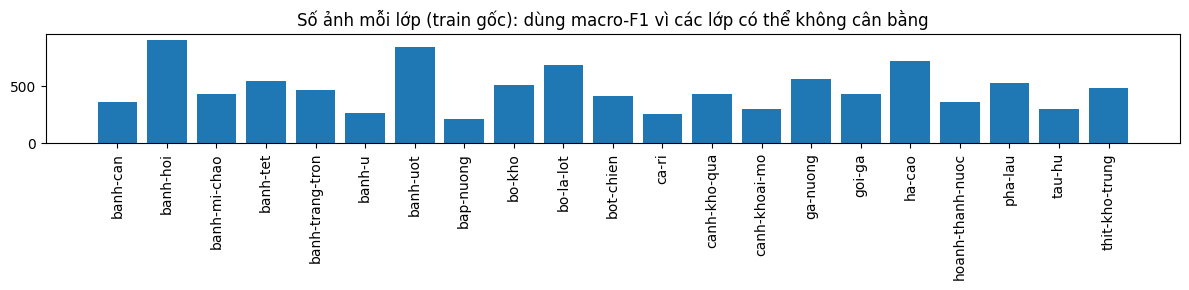

In [4]:
# Kiểm tra dữ liệu: shape một ảnh / một batch và phân phối lớp (Lab 2, A.2 Bước 5)
if READY:
    train_dl, val_dl, test_dl = get_loaders(IMG_SIZE, augment=True)
    print("số lớp         :", NUM_CLASSES)
    print("train/val/test :", len(train_dl.dataset), "/", len(val_dl.dataset), "/", len(test_dl.dataset))
    print("thứ tự lớp     :", CLASSES[:5], "...")

    anh, nhan = train_dl.dataset[0]
    xb, yb = next(iter(train_dl))
    show("một ảnh sau transform", anh)
    show("một batch vào model", xb)
    show("nhãn", yb)

    counts = np.bincount(datasets.ImageFolder(DATA_ROOT / "train").targets, minlength=NUM_CLASSES)
    print(f"\nảnh/lớp (train gốc): min {counts.min()}, max {counts.max()}, tỉ lệ max/min {counts.max() / counts.min():.2f}")
    plt.figure(figsize=(12, 3))
    plt.bar(range(NUM_CLASSES), counts)
    plt.xticks(range(NUM_CLASSES), CLASSES, rotation=90)
    plt.title("Số ảnh mỗi lớp (train gốc): dùng macro-F1 vì các lớp có thể không cân bằng")
    plt.tight_layout()
    plt.show()
else:
    print("Chưa có dữ liệu: các ô huấn luyện sẽ tự bỏ qua, phần kiểm tra kiến trúc vẫn chạy.")

In [5]:
# Khung huấn luyện và đánh giá (Lab 2, B.7)
def train_one_epoch(model, loader, criterion, optimizer, device):
    model.train()                     # bật dropout, BN dùng thống kê batch
    total, correct, running = 0, 0, 0.0
    for xb, yb in loader:
        xb, yb = xb.to(device), yb.to(device)
        optimizer.zero_grad()
        logits = model(xb)
        loss = criterion(logits, yb)
        loss.backward()
        optimizer.step()

        running += loss.item() * yb.size(0)
        correct += (logits.argmax(1) == yb).sum().item()
        total += yb.size(0)
    return running / total, correct / total


@torch.no_grad()
def evaluate(model, loader, criterion, device):
    model.eval()                      # tắt dropout, BN dùng thống kê tích luỹ
    total, correct, running = 0, 0, 0.0
    y_true, y_pred = [], []
    for xb, yb in loader:
        xb, yb = xb.to(device), yb.to(device)
        logits = model(xb)
        running += criterion(logits, yb).item() * yb.size(0)
        pred = logits.argmax(1)
        correct += (pred == yb).sum().item()
        total += yb.size(0)
        y_true += yb.cpu().tolist()
        y_pred += pred.cpu().tolist()
    return running / total, correct / total, y_true, y_pred


def fit(model, train_dl, val_dl, criterion, optimizer, epochs):
    # Huấn luyện, ghi lịch sử; cuối cùng nạp lại trọng số của epoch có val loss thấp nhất
    hist = {"train_loss": [], "train_acc": [], "val_loss": [], "val_acc": [], "sec": []}
    best_loss, best_state = float("inf"), None
    for ep in range(1, epochs + 1):
        t0 = time.perf_counter()
        tr_loss, tr_acc = train_one_epoch(model, train_dl, criterion, optimizer, device)
        va_loss, va_acc, _, _ = evaluate(model, val_dl, criterion, device)
        hist["sec"].append(time.perf_counter() - t0)
        for k, v in zip(("train_loss", "train_acc", "val_loss", "val_acc"), (tr_loss, tr_acc, va_loss, va_acc)):
            hist[k].append(v)
        if va_loss < best_loss:
            best_loss, hist["best_epoch"] = va_loss, ep
            best_state = {k: v.detach().clone() for k, v in model.state_dict().items()}
        print(f"epoch {ep:>2}  train {tr_loss:.4f}/{tr_acc:.4f}   val {va_loss:.4f}/{va_acc:.4f}   {hist['sec'][-1]:.1f}s")
    model.load_state_dict(best_state)
    return hist


def split_epoch(hist, thr=0.1):
    # Epoch đầu tiên val loss vượt train loss quá thr (tương đối): hai đường bắt đầu tách nhau
    for ep, (t, v) in enumerate(zip(hist["train_loss"], hist["val_loss"]), 1):
        if v > (1 + thr) * t:
            return ep
    return None


def plot_curves(hist, title, mark_split=False):
    ep = range(1, len(hist["train_loss"]) + 1)
    fig, ax = plt.subplots(1, 2, figsize=(12, 3.5))
    ax[0].plot(ep, hist["train_loss"], label="train loss")
    ax[0].plot(ep, hist["val_loss"], label="val loss")
    ax[0].axvline(hist["best_epoch"], color="gray", ls=":", label=f"val loss thấp nhất (epoch {hist['best_epoch']})")
    se = split_epoch(hist)
    if mark_split and se:
        ax[0].axvline(se, color="red", ls="--", label=f"hai đường tách nhau (epoch {se})")
    ax[0].set_xlabel("epoch")
    ax[0].set_ylabel("loss")
    ax[0].legend()
    ax[1].plot(ep, hist["train_acc"], label="train acc")
    ax[1].plot(ep, hist["val_acc"], label="val acc")
    ax[1].set_xlabel("epoch")
    ax[1].set_ylabel("accuracy")
    ax[1].legend()
    fig.suptitle(title)
    plt.tight_layout()
    plt.show()


RESULTS = {}   # tag -> dict kết quả, dùng cho bảng tổng hợp
RESULTS_DIR = Path("results")   # mỗi lần chạy lưu 1 file json để các notebook/bài khác đọc lại khi so sánh
RESULTS_DIR.mkdir(exist_ok=True)


def save_result(tag):
    slug = "".join(ch if ch.isalnum() else "_" for ch in tag.lower())
    light = {k: v for k, v in RESULTS[tag].items() if k not in ("y_true", "y_pred")}
    with open(RESULTS_DIR / f"{slug}.json", "w", encoding="utf-8") as f:
        json.dump({"tag": tag, **light}, f, ensure_ascii=False, default=float)


def load_results():
    for p in sorted(RESULTS_DIR.glob("*.json")):
        with open(p, encoding="utf-8") as f:
            r = json.load(f)
        RESULTS.setdefault(r.pop("tag"), r)


def show_report(tag, res, mark_split=False):
    hist, y_true, y_pred = res["hist"], res["y_true"], res["y_pred"]
    print(f"\n--- {tag}: kết quả trên tập test (nạp lại epoch {hist['best_epoch']}) ---")
    print(f"tham số: {res['params']:,} (được học: {res['trainable']:,}) | {res['sec_epoch']:.1f} giây/epoch")
    display(pd.DataFrame({
        "accuracy": [res["accuracy"]], "precision (macro)": [res["precision"]],
        "recall (macro)": [res["recall"]], "F1 (macro)": [res["macro_f1"]],
    }, index=[tag]).round(4))

    p, r, f, s = precision_recall_fscore_support(
        y_true, y_pred, labels=list(range(NUM_CLASSES)), average=None, zero_division=0)
    display(pd.DataFrame({"lớp": CLASSES, "precision": p, "recall": r, "F1": f, "số ảnh test": s}).round(4))

    plot_curves(hist, tag, mark_split)

    cm = confusion_matrix(y_true, y_pred, labels=list(range(NUM_CLASSES)))
    plt.figure(figsize=(13, 11))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=CLASSES, yticklabels=CLASSES,
                annot_kws={"size": 6}, cbar=False)
    plt.xlabel("dự đoán")
    plt.ylabel("thực tế")
    plt.title(f"Confusion matrix {NUM_CLASSES}x{NUM_CLASSES}: {tag}")
    plt.tight_layout()
    plt.show()

    off = cm.copy()
    np.fill_diagonal(off, 0)
    print("Top 5 cặp bị nhầm nhiều nhất (thực tế -> dự đoán):")
    for i, j in zip(*np.unravel_index(np.argsort(-off, axis=None)[:5], off.shape)):
        if off[i, j] > 0:
            print(f"  {CLASSES[i]} -> {CLASSES[j]}: {off[i, j]} ảnh")


def train_and_report(tag, make_model, img_size, lr, epochs, augment=True, mark_split=False):
    # Một lần chạy hoàn chỉnh: tạo model -> Adam -> huấn luyện -> đánh giá test -> báo cáo
    if not READY:
        print(f"[{tag}] chưa có dữ liệu VinaFood21 -> bỏ qua huấn luyện.")
        return None
    train_dl, val_dl, test_dl = get_loaders(img_size, augment)
    seed_everything()
    model = make_model().to(device)
    criterion = nn.CrossEntropyLoss()
    optimizer = torch.optim.Adam([p for p in model.parameters() if p.requires_grad], lr=lr)   # chỉ tham số cần học
    print(f"== {tag} | resize {img_size} | augment={augment} | Adam lr={lr} | "
          f"tham số {n_params(model):,} (được học {n_params(model, True):,})")

    hist = fit(model, train_dl, val_dl, criterion, optimizer, epochs)
    _, _, y_true, y_pred = evaluate(model, test_dl, criterion, device)
    p, r, f1, _ = precision_recall_fscore_support(y_true, y_pred, average="macro", zero_division=0)
    RESULTS[tag] = dict(
        resize=f"{img_size}x{img_size}", params=n_params(model), trainable=n_params(model, True),
        sec_epoch=float(np.mean(hist["sec"])), accuracy=accuracy_score(y_true, y_pred),
        precision=p, recall=r, macro_f1=f1, hist=hist, y_true=y_true, y_pred=y_pred)
    save_result(tag)
    show_report(tag, RESULTS[tag], mark_split)
    return model


def compare_models(names):
    names = [n for n in names if n in RESULTS]
    return pd.DataFrame({
        n: {"tham số": RESULTS[n]["params"], "giây/epoch": RESULTS[n]["sec_epoch"],
            "accuracy": RESULTS[n]["accuracy"], "macro-F1": RESULTS[n]["macro_f1"]}
        for n in names}).T.round(4)


load_results()   # nạp kết quả các bài đã chạy trước đó (nếu có)

### Bài 3*: Xây dựng mô hình ResNet-18, đánh giá mô hình ResNet-18 trên bộ dữ liệu VinaFood21 sử dụng các độ đo precision, recall, và F1 (Sử dụng Adam làm optimizer).

**ResNet Block**

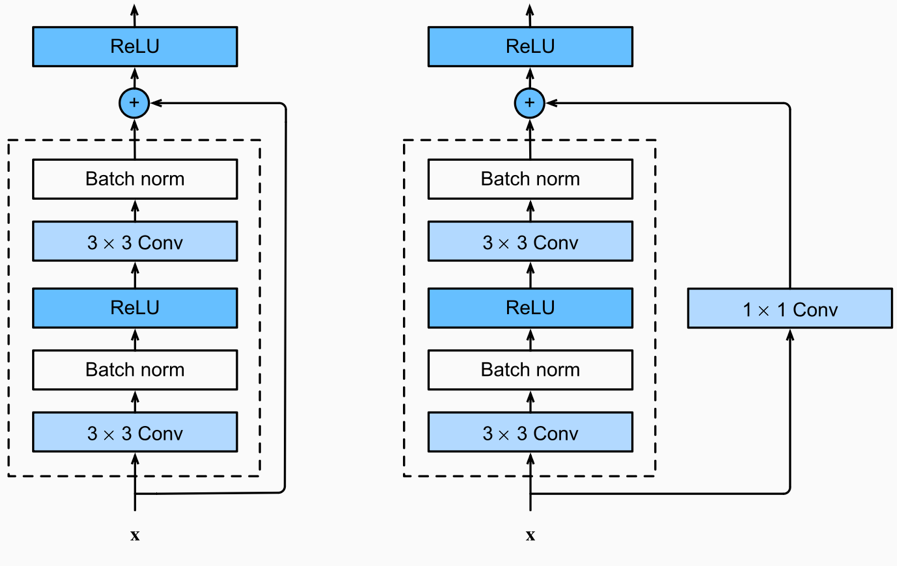

**ResNet**

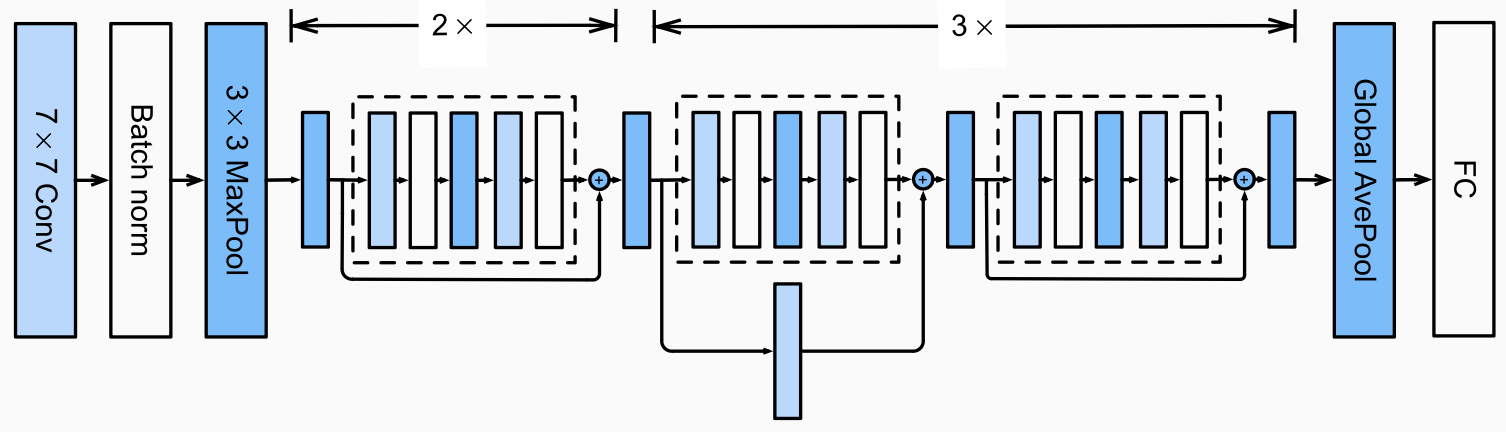

#### Lời giải Bài 3*: ResNet-18 từ đầu

ResNet-18 `[2, 2, 2, 2]` BasicBlock, shortcut identity khi khớp shape, projection conv 1×1 + BN khi đổi. Huấn luyện từ đầu (không pretrained), ảnh **96×96** (64×64 chỉ còn 2×2 ở layer4), chạy hai lần: có và không có augmentation.

In [6]:
# BasicBlock và ResNet-18 (Lab 2, B.5 Bước 1 và 3)
class BasicBlock(nn.Module):
    def __init__(self, in_ch, out_ch, stride=1):
        super().__init__()
        self.conv1 = nn.Conv2d(in_ch, out_ch, 3, stride, padding=1, bias=False)
        self.bn1 = nn.BatchNorm2d(out_ch)
        self.conv2 = nn.Conv2d(out_ch, out_ch, 3, 1, padding=1, bias=False)
        self.bn2 = nn.BatchNorm2d(out_ch)

        self.shortcut = nn.Identity()
        if stride != 1 or in_ch != out_ch:       # cần projection
            self.shortcut = nn.Sequential(
                nn.Conv2d(in_ch, out_ch, 1, stride, bias=False),
                nn.BatchNorm2d(out_ch))

    def forward(self, x):
        out = torch.relu(self.bn1(self.conv1(x)))
        out = self.bn2(self.conv2(out))
        out = out + self.shortcut(x)             # cộng trước
        return torch.relu(out)                   # ReLU sau


class ResNet18(nn.Module):
    def __init__(self, num_classes=21):
        super().__init__()
        self.stem = nn.Sequential(
            nn.Conv2d(3, 64, 7, stride=2, padding=3, bias=False),
            nn.BatchNorm2d(64), nn.ReLU(),
            nn.MaxPool2d(3, stride=2, padding=1))
        self.layer1 = self._stage(64, 64, stride=1)
        self.layer2 = self._stage(64, 128, stride=2)
        self.layer3 = self._stage(128, 256, stride=2)
        self.layer4 = self._stage(256, 512, stride=2)
        self.pool = nn.AdaptiveAvgPool2d(1)
        self.fc = nn.Linear(512, num_classes)

    @staticmethod
    def _stage(in_ch, out_ch, stride):
        # Block đầu chịu trách nhiệm đổi channel và giảm chiều
        return nn.Sequential(BasicBlock(in_ch, out_ch, stride), BasicBlock(out_ch, out_ch, 1))

    def forward(self, x):
        x = self.stem(x)
        for layer in (self.layer1, self.layer2, self.layer3, self.layer4):
            x = layer(x)
        return self.fc(self.pool(x).flatten(1))


# Bảng shape và tham số qua từng stage với ảnh vào 96x96
r18 = ResNet18(num_classes=NUM_CLASSES).eval()
x = torch.rand(1, 3, R18_SIZE, R18_SIZE)
print(f"{'stage':<10}{'output shape':<20}{'tham số':>12}")
with torch.no_grad():
    x = r18.stem(x)
    print(f"{'stem':<10}{str(tuple(x.shape)):<20}{n_params(r18.stem):>12,}")
    for name in ("layer1", "layer2", "layer3", "layer4"):
        layer = getattr(r18, name)
        x = layer(x)
        print(f"{name:<10}{str(tuple(x.shape)):<20}{n_params(layer):>12,}")
print(f"{'fc':<10}{str((1, NUM_CLASSES)):<20}{n_params(r18.fc):>12,}")
print(f"{'TỔNG':<10}{'':<20}{n_params(r18):>12,}")

assert tuple(x.shape) == (1, 512, 3, 3)
assert n_params(ResNet18(21)) == 11_187_285          # đối chiếu số liệu của Lab 2

# Đối chiếu với torchvision (không tải trọng số)
from torchvision.models import resnet18 as tv_resnet18
tv = tv_resnet18(weights=None)
tv.fc = nn.Linear(512, 21)
assert n_params(tv) == n_params(ResNet18(21))
print("Khớp số tham số với torchvision resnet18 (fc 21 lớp):", f"{n_params(tv):,}")

stage     output shape             tham số
stem      (1, 64, 24, 24)            9,536
layer1    (1, 64, 24, 24)          147,968
layer2    (1, 128, 12, 12)         525,568
layer3    (1, 256, 6, 6)         2,099,712
layer4    (1, 512, 3, 3)         8,393,728
fc        (1, 21)                   10,773
TỔNG                            11,187,285
Khớp số tham số với torchvision resnet18 (fc 21 lớp): 11,187,285


== ResNet-18 từ đầu (có augment) | resize 96 | augment=True | Adam lr=0.001 | tham số 11,187,285 (được học 11,187,285)


/usr/local/lib/python3.13/dist-packages/PIL/Image.py:1134: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(


epoch  1  train 2.7246/0.1844   val 2.5469/0.2171   71.1s


/usr/local/lib/python3.13/dist-packages/PIL/Image.py:1134: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(


epoch  2  train 2.4647/0.2431   val 2.3317/0.3088   70.5s


...

epoch 19  train 1.1181/0.6386   val 1.4098/0.5548   70.1s


/usr/local/lib/python3.13/dist-packages/PIL/Image.py:1134: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(


epoch 20  train 1.0737/0.6501   val 1.4201/0.5508   70.9s

--- ResNet-18 từ đầu (có augment): kết quả trên tập test (nạp lại epoch 19) ---
tham số: 11,187,285 (được học: 11,187,285) | 70.5 giây/epoch


,accuracy,precision (macro),recall (macro),F1 (macro)
ResNet-18 từ đầu (có augment),0.4924,0.5033,0.4812,0.4817


,lớp,precision,recall,F1,số ảnh test
0,banh-can,0.5411,0.3278,0.4083,241
1,banh-hoi,0.4936,0.6326,0.5545,607
2,banh-mi-chao,0.6221,0.4671,0.5336,289
3,banh-tet,0.6943,0.4368,0.5363,364
4,banh-trang-tron,0.3504,0.4207,0.3824,309
5,banh-u,0.4737,0.4602,0.4669,176
6,banh-uot,0.4365,0.4786,0.4566,560
7,bap-nuong,0.2881,0.3566,0.3188,143
8,bo-kho,0.4779,0.5444,0.5090,338
9,bo-la-lot,0.4734,0.8559,0.6096,458


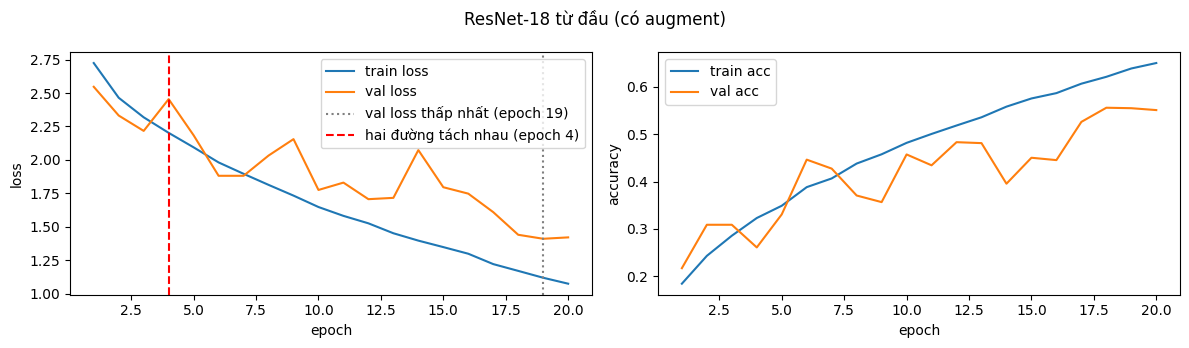

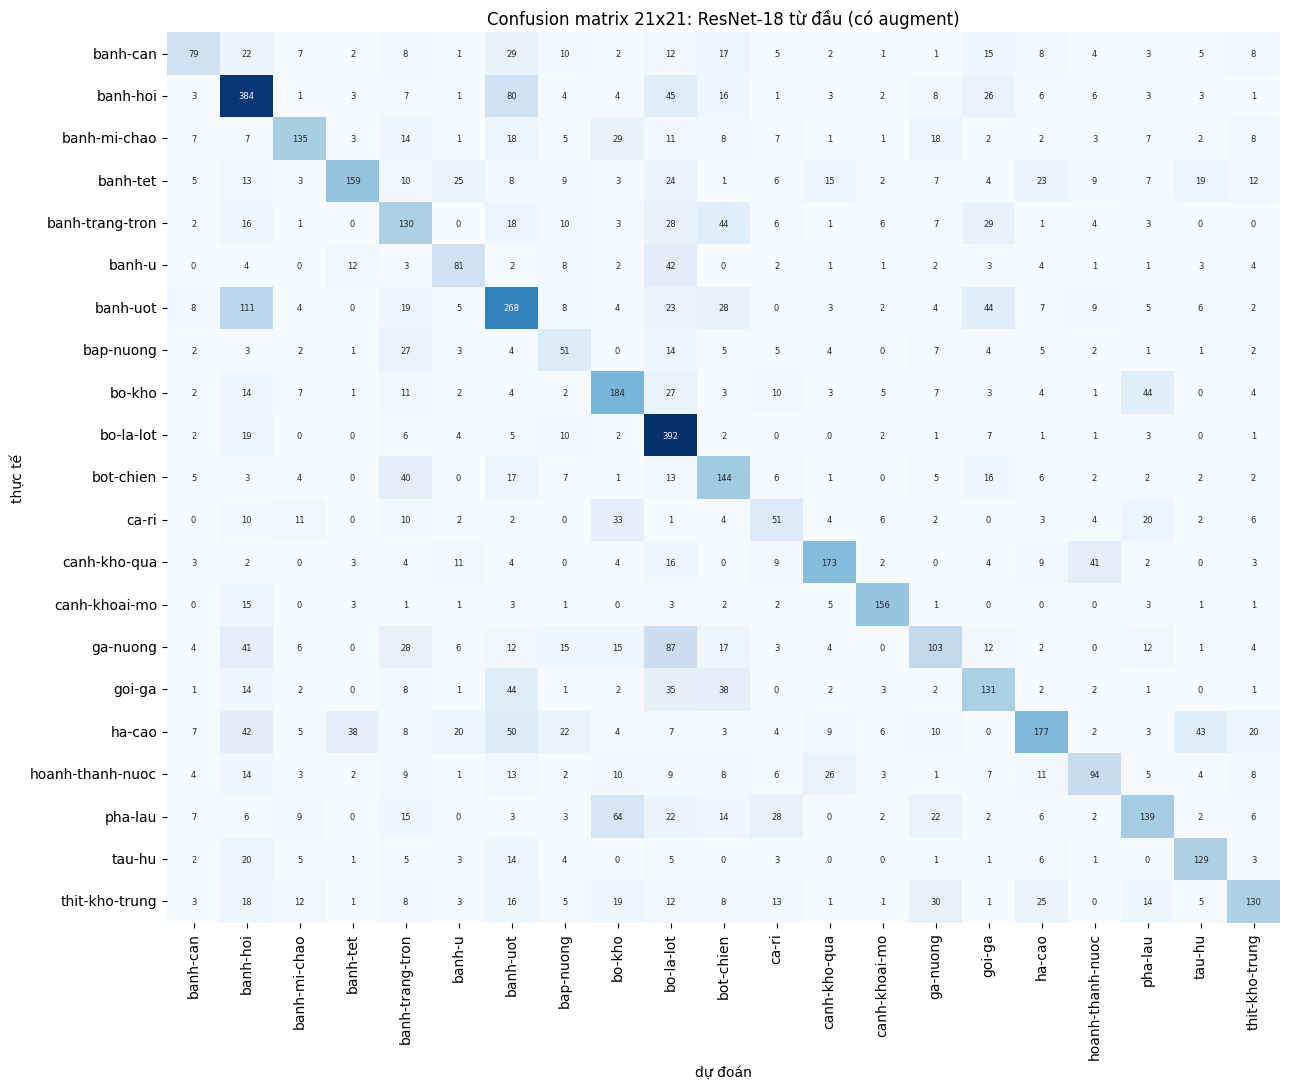

Top 5 cặp bị nhầm nhiều nhất (thực tế -> dự đoán):
  banh-uot -> banh-hoi: 111 ảnh
  ga-nuong -> bo-la-lot: 87 ảnh
  banh-hoi -> banh-uot: 80 ảnh
  pha-lau -> bo-kho: 64 ảnh
  ha-cao -> banh-uot: 50 ảnh


In [7]:
# Lần 1: có augmentation (Adam, lr 1e-3, 96x96)
_ = train_and_report("ResNet-18 từ đầu (có augment)", lambda: ResNet18(NUM_CLASSES),
                     R18_SIZE, lr=1e-3, epochs=EPOCHS, augment=True, mark_split=True)

== ResNet-18 từ đầu (không augment) | resize 96 | augment=False | Adam lr=0.001 | tham số 11,187,285 (được học 11,187,285)


/usr/local/lib/python3.13/dist-packages/PIL/Image.py:1134: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(


epoch  1  train 2.6501/0.2049   val 2.4341/0.2729   67.4s


/usr/local/lib/python3.13/dist-packages/PIL/Image.py:1134: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(


epoch  2  train 2.3386/0.2793   val 2.2957/0.2958   68.4s


...

epoch 19  train 0.0960/0.9688   val 3.0052/0.4861   66.9s


/usr/local/lib/python3.13/dist-packages/PIL/Image.py:1134: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(


epoch 20  train 0.1050/0.9638   val 2.9444/0.4801   67.5s

--- ResNet-18 từ đầu (không augment): kết quả trên tập test (nạp lại epoch 7) ---
tham số: 11,187,285 (được học: 11,187,285) | 67.4 giây/epoch


,accuracy,precision (macro),recall (macro),F1 (macro)
ResNet-18 từ đầu (không augment),0.3842,0.405,0.3656,0.3579


,lớp,precision,recall,F1,số ảnh test
0,banh-can,0.4000,0.1494,0.2175,241
1,banh-hoi,0.3661,0.5700,0.4459,607
2,banh-mi-chao,0.5254,0.3218,0.3991,289
3,banh-tet,0.4832,0.3159,0.3821,364
4,banh-trang-tron,0.4375,0.0680,0.1176,309
5,banh-u,0.2432,0.2045,0.2222,176
6,banh-uot,0.2907,0.2964,0.2935,560
7,bap-nuong,0.3529,0.0839,0.1356,143
8,bo-kho,0.3638,0.5059,0.4233,338
9,bo-la-lot,0.5092,0.6638,0.5763,458


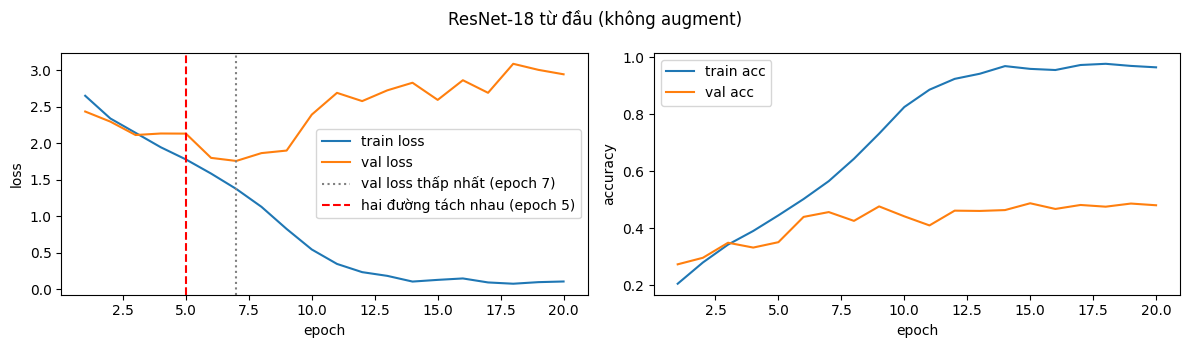

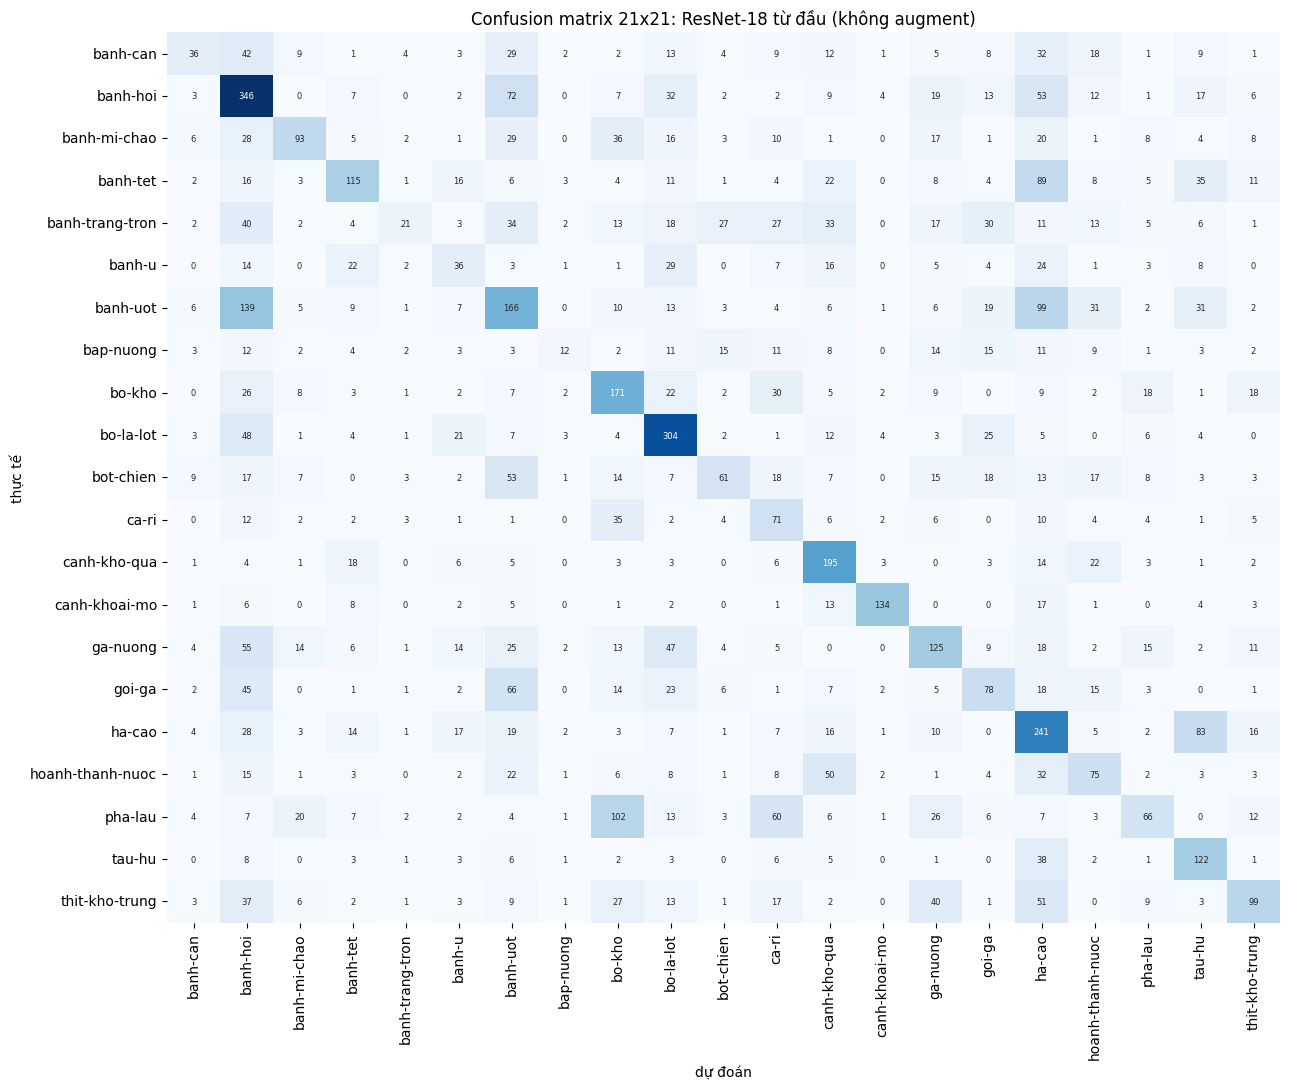

Top 5 cặp bị nhầm nhiều nhất (thực tế -> dự đoán):
  banh-uot -> banh-hoi: 139 ảnh
  pha-lau -> bo-kho: 102 ảnh
  banh-uot -> ha-cao: 99 ảnh
  banh-tet -> ha-cao: 89 ảnh
  ha-cao -> tau-hu: 83 ảnh


,tham số,giây/epoch,accuracy,macro-F1
ResNet-18 từ đầu (có augment),11187285.0,70.5041,0.4924,0.4817
ResNet-18 từ đầu (không augment),11187285.0,67.3684,0.3842,0.3579


ResNet-18 từ đầu (có augment): hai đường bắt đầu tách nhau (val loss > 1.1 x train loss) ở epoch 4; val loss thấp nhất ở epoch 19
ResNet-18 từ đầu (không augment): hai đường bắt đầu tách nhau (val loss > 1.1 x train loss) ở epoch 5; val loss thấp nhất ở epoch 7
macro-F1: có augment 0.4817 | không augment 0.3579 | chênh +0.1238


In [8]:
# Lần 2: không augmentation (cùng seed, cùng phép chia dữ liệu)
_ = train_and_report("ResNet-18 từ đầu (không augment)", lambda: ResNet18(NUM_CLASSES),
                     R18_SIZE, lr=1e-3, epochs=EPOCHS, augment=False, mark_split=True)

aug, noaug = "ResNet-18 từ đầu (có augment)", "ResNet-18 từ đầu (không augment)"
display(compare_models([aug, noaug, "LeNet-5 (AvgPool)", "LeNet-5 (MaxPool)"]))
if {aug, noaug} <= RESULTS.keys():
    for tag in (aug, noaug):
        h = RESULTS[tag]["hist"]
        print(f"{tag}: hai đường bắt đầu tách nhau (val loss > 1.1 x train loss) ở epoch {split_epoch(h)}; "
              f"val loss thấp nhất ở epoch {h['best_epoch']}")
    d = RESULTS[aug]["macro_f1"] - RESULTS[noaug]["macro_f1"]
    print(f"macro-F1: có augment {RESULTS[aug]['macro_f1']:.4f} | không augment {RESULTS[noaug]['macro_f1']:.4f} | chênh {d:+.4f}")

**Nhận xét Bài 3** (điền số sau khi chạy)

- Số tham số 11,187,285 (≈ 33 lần LeNet), layer4 ở 96×96 ra (512, 3, 3), khớp torchvision.
- Đường loss: lần không augment hai đường tách nhau từ epoch …, lần có augment từ epoch … (xem biểu đồ, đường đứt đỏ).
- Chênh macro-F1 giữa hai lần chạy: … Giải thích: với khoảng 14 nghìn ảnh, mạng 11 triệu tham số học từ đầu dễ ghi nhớ tập train; augmentation làm train loss khó giảm hơn nhưng thu hẹp khoảng cách với val. Kết quả thấp hơn kỳ vọng không có nghĩa là cài sai.

---
## Bảng tổng hợp kết quả

In [9]:
# Bảng tổng hợp lấy từ các lần chạy ở trên (Lab 2, C.2)
ORDER = ["LeNet-5 (AvgPool)", "LeNet-5 (MaxPool)", "GoogLeNet rút gọn", "ResNet-18 từ đầu (có augment)",
         "ResNet-18 từ đầu (không augment)", "ResNet-50 feature extraction", "ResNet-50 fine-tuning"]
rows = [{
    "Mô hình": tag, "Resize": r["resize"], "Tham số": f"{r['params']:,}",
    "Tham số được học": f"{r['trainable']:,}", "Giây/epoch": round(r["sec_epoch"], 1),
    "Accuracy": round(r["accuracy"], 4), "macro-F1": round(r["macro_f1"], 4),
} for tag, r in sorted(RESULTS.items(), key=lambda kv: ORDER.index(kv[0]) if kv[0] in ORDER else 99)]

if rows:
    summary = pd.DataFrame(rows)
    display(summary)
    summary.to_csv("ket_qua_tong_hop.csv", index=False)
else:
    print("Chưa có kết quả huấn luyện (thiếu dữ liệu).")

,Mô hình,Resize,Tham số,Tham số được học,Giây/epoch,Accuracy,macro-F1
0,ResNet-18 từ đầu (có augment),96x96,"11,187,285","11,187,285",70.5,0.4924,0.4817
1,ResNet-18 từ đầu (không augment),96x96,"11,187,285","11,187,285",67.4,0.3842,0.3579
